BatteryMind AI environment initialized.
Dataset archive already exists.

NASA battery files located:
B0005 -> /content/BatteryMind_AI/data/extracted/5. Battery Data Set/1. BatteryAgingARC-FY08Q4_contents/B0005.mat
B0006 -> /content/BatteryMind_AI/data/extracted/5. Battery Data Set/1. BatteryAgingARC-FY08Q4_contents/B0006.mat
B0007 -> /content/BatteryMind_AI/data/extracted/5. Battery Data Set/1. BatteryAgingARC-FY08Q4_contents/B0007.mat
B0018 -> /content/BatteryMind_AI/data/extracted/5. Battery Data Set/1. BatteryAgingARC-FY08Q4_contents/B0018.mat

Processing B0005...

Processing B0006...

Processing B0007...

Processing B0018...

Battery dataset extraction successful.
Dataset shape: (636, 14)
  battery_id  cycle_index  capacity_ah  ambient_temperature  voltage_mean  \
0      B0005            1     1.856487                 24.0      3.529829   
1      B0005            2     1.846327                 24.0      3.537320   
2      B0005            3     1.835349                 24.0      3.

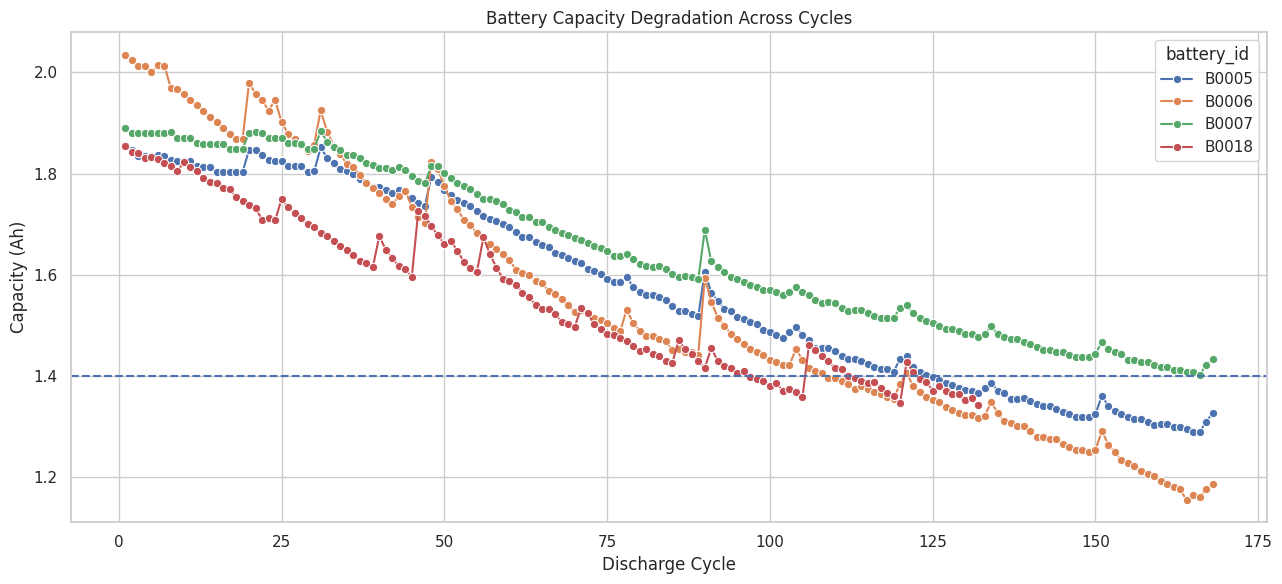

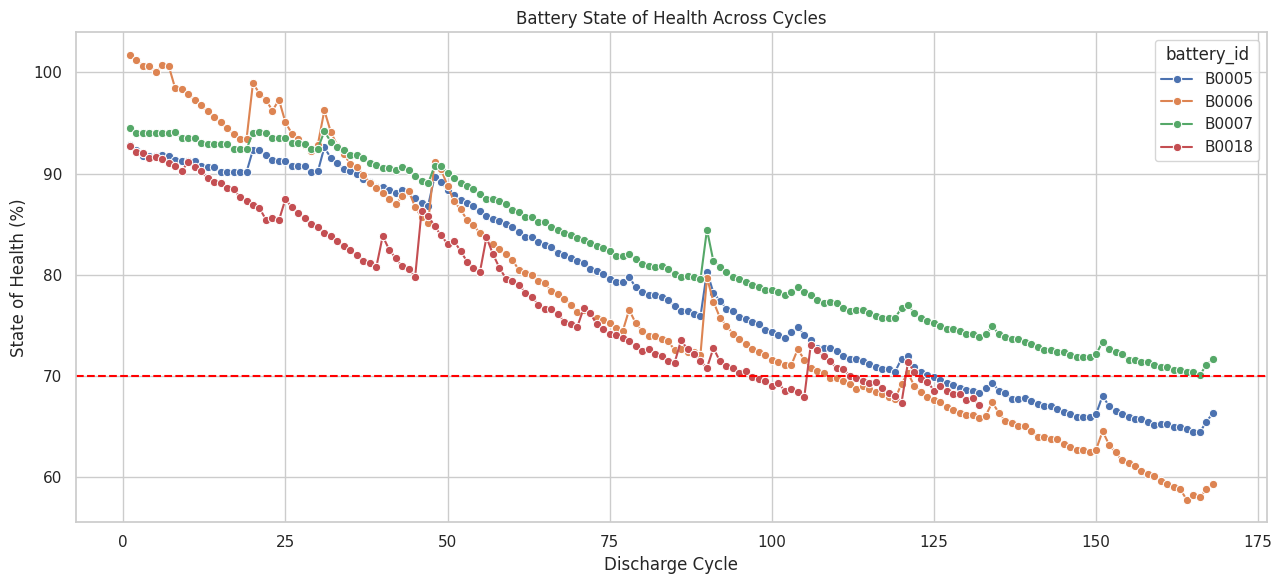


BATTERY COMPARISON
  battery_id  total_cycles  initial_capacity  final_capacity  average_soh  \
0      B0005           168          1.856487        1.325079    78.625103   
1      B0006           168          2.035338        1.185675    77.342533   
2      B0007           168          1.891052        1.432455    82.221070   
3      B0018           132          1.855005        1.341051    77.885038   

   average_temperature  capacity_loss  
0            32.791319       0.531408  
1            32.792665       0.849662  
2            32.367751       0.458597  
3            31.094192       0.513953  


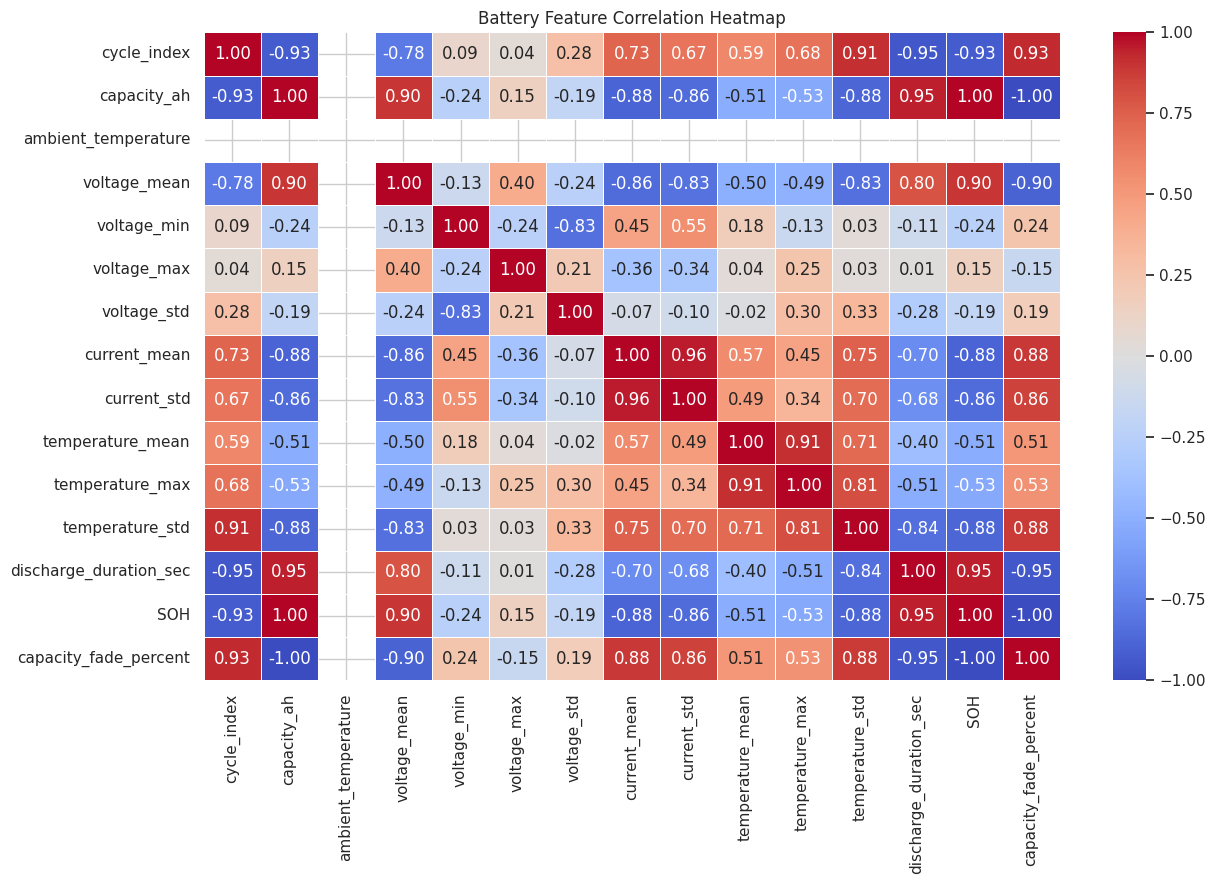


Feature engineering completed.
Total features: 15

STARTING SOH MODEL TRAINING

Evaluating: Random Forest

Evaluating: Extra Trees

Evaluating: Gradient Boosting

SOH MODEL COMPARISON
               Model       MAE      RMSE        R2
0        Extra Trees  1.729013  2.291496  0.946752
1  Gradient Boosting  2.010424  2.537156  0.934723
2      Random Forest  2.377478  2.923469  0.913331

Best SOH model: Extra Trees


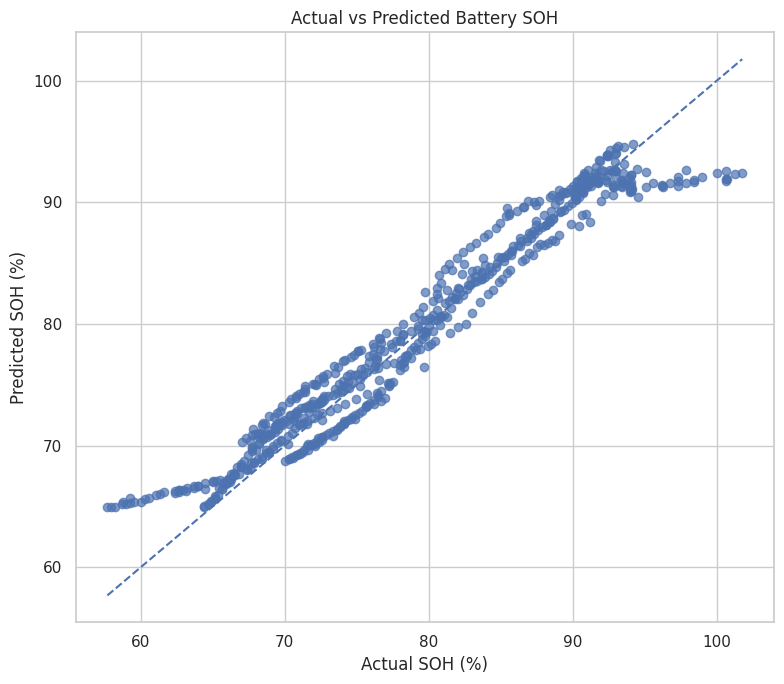

B0007: EOL threshold not observed; RUL labels unavailable.

RUL LABEL SUMMARY
            count  min    max
battery_id                   
B0005         168  0.0  124.0
B0006         168  0.0  108.0
B0007           0  NaN    NaN
B0018         132  0.0   96.0

Evaluating: Random Forest

Evaluating: Extra Trees

Evaluating: Gradient Boosting

RUL MODEL COMPARISON
               Model        MAE       RMSE        R2
0        Extra Trees   9.432698  12.035684  0.896275
1      Random Forest  10.128539  13.215862  0.874936
2  Gradient Boosting  10.939559  13.878633  0.862078

Best RUL model: Extra Trees


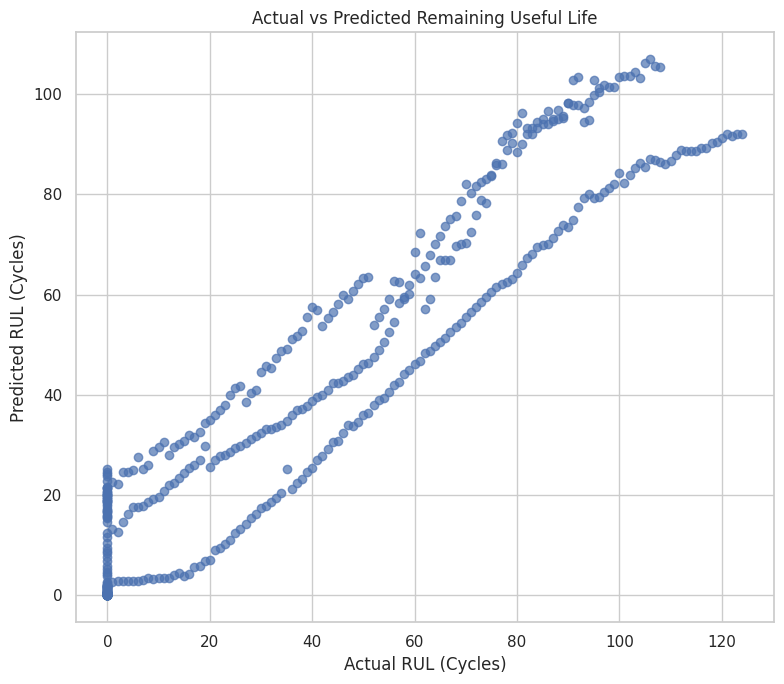


ANOMALY SUMMARY
anomaly_status
Normal               604
Potential Anomaly     32
Name: count, dtype: int64


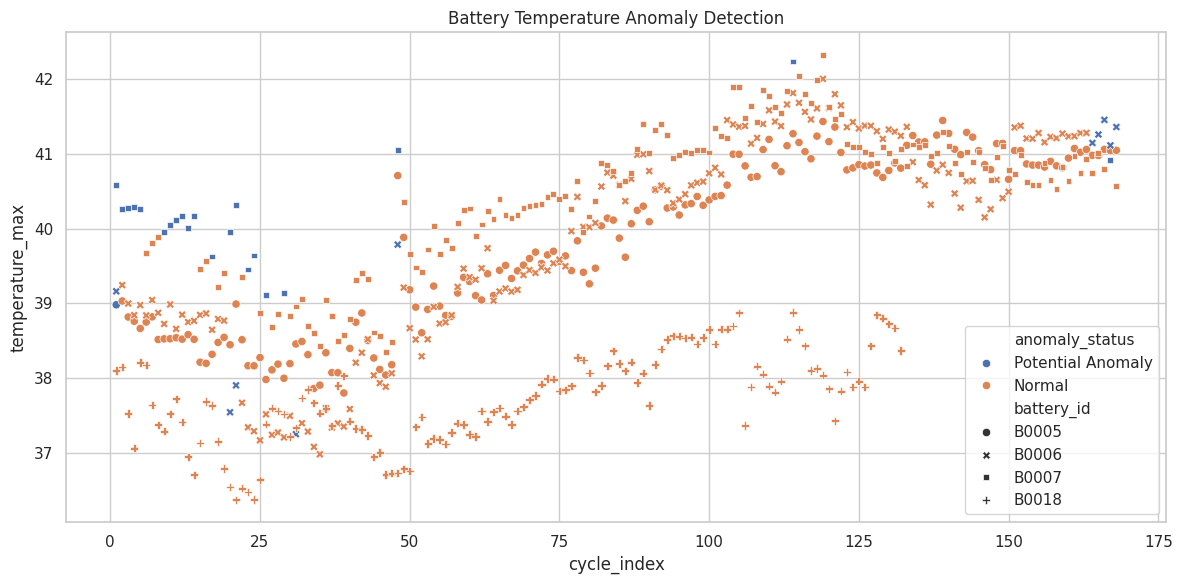


Calculating SOH feature importance...
                   Feature    Importance  Importance_std
13  discharge_duration_sec  3.581523e+00    6.359359e-02
14          cycle_progress  1.815260e+00    4.345067e-02
8              current_std  1.442780e+00    3.033925e-02
7             current_mean  1.405148e+00    2.787538e-02
0              cycle_index  1.336936e+00    3.660148e-02
2             voltage_mean  9.541818e-01    1.673817e-02
11         temperature_std  2.185852e-01    6.407310e-03
4              voltage_max  4.804598e-02    2.845622e-03
6            voltage_range  4.240253e-02    1.474242e-03
12       temperature_range  3.924326e-02    1.603450e-03
3              voltage_min  3.783990e-02    1.571547e-03
10         temperature_max  3.494420e-02    1.697168e-03
5              voltage_std  3.371494e-02    2.190748e-03
9         temperature_mean  2.394571e-02    1.324775e-03
1      ambient_temperature -3.087808e-16    4.236165e-16


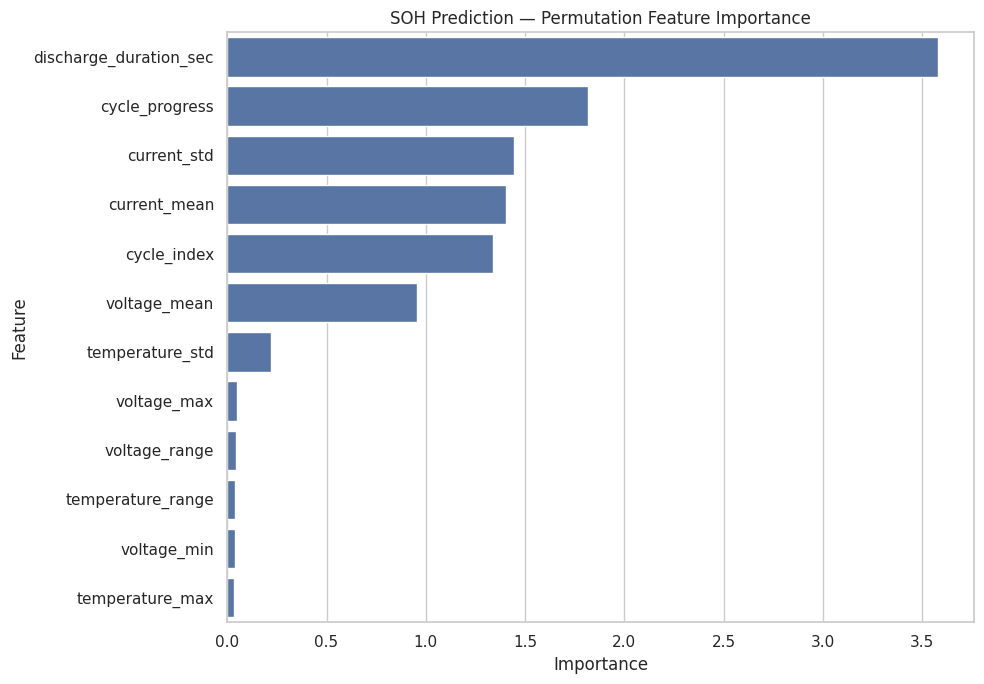

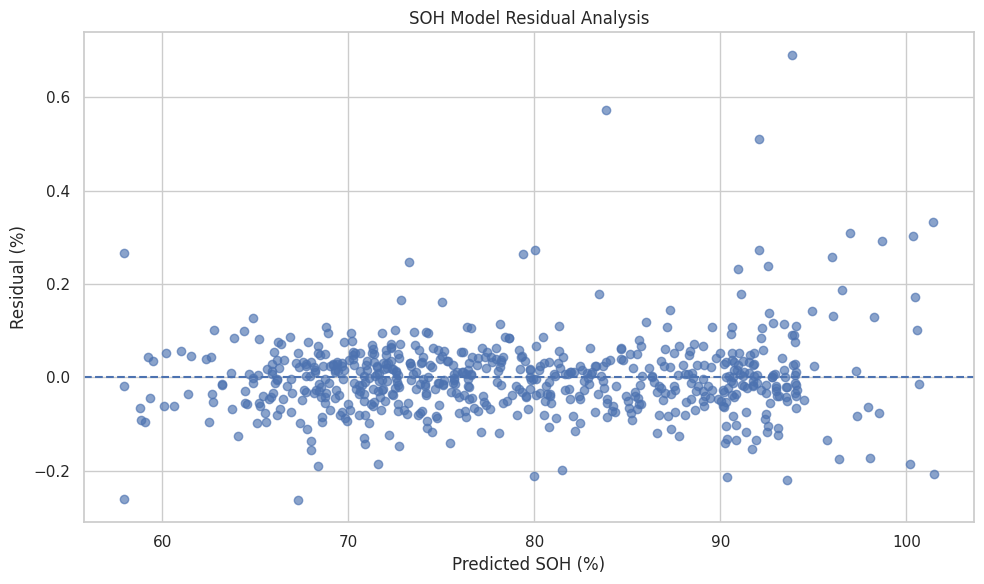


CUSTOM BATTERY HEALTH PREDICTION

Enter a battery profile.
Press ENTER to use the corresponding example value.
cycle_index [132.0000]: 
ambient_temperature [24.0000]: 
voltage_mean [3.4479]: 
voltage_min [2.3656]: 
voltage_max [4.1858]: 
voltage_std [0.2634]: 
voltage_range [1.8202]: 
current_mean [-1.7777]: 
current_std [0.6407]: 
temperature_mean [31.2762]: 
temperature_max [38.3718]: 
temperature_std [4.0288]: 
temperature_range [7.0956]: 
discharge_duration_sec [2742.8430]: 
cycle_progress [1.0000]: 

       BATTERYMIND AI REPORT
Predicted State of Health: 67.31%
Model estimate: Below the 70% SOH reference
Predicted Remaining Useful Life: 0.0 cycles
Note: These are research-model estimates, not certified battery diagnostics.

Models saved successfully.

BATTERYMIND  COMPLETED
Dataset records: 636
Battery cells: 4
SOH best model: Extra Trees
SOH MAE: 1.729
SOH RMSE: 2.2915
SOH R2: 0.9468

Project ZIP: /content/BatteryMind_AI_Day11.zip
All outputs saved inside BatteryMind_AI.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


BatteryMind  execution finished.


In [ ]:
# Environment: Google Colab
# ================================================================

# ================================================================
# 01. INSTALLATION AND IMPORTS
# ================================================================

!pip -q install scipy scikit-learn seaborn joblib requests

import os
import io
import zipfile
import warnings
import requests
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy.io import loadmat

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    IsolationForest
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

BASE_DIR = Path("/content/BatteryMind_AI")
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
MODEL_DIR = BASE_DIR / "models"
REPORT_DIR = BASE_DIR / "reports"

for folder in [DATA_DIR, OUTPUT_DIR, MODEL_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("BatteryMind AI environment initialized.")

# ================================================================
# 02. DOWNLOAD NASA DATASET AUTOMATICALLY
# ================================================================

DATA_URL = (
    "https://phm-datasets.s3.amazonaws.com/"
    "NASA/5.+Battery+Data+Set.zip"
)

ZIP_PATH = DATA_DIR / "NASA_Battery_Dataset.zip"

if not ZIP_PATH.exists():
    print("Downloading original NASA battery dataset...")

    response = requests.get(
        DATA_URL,
        timeout=180
    )

    response.raise_for_status()

    with open(ZIP_PATH, "wb") as file:
        file.write(response.content)

    print("Download completed.")

else:
    print("Dataset archive already exists.")

# Extract archives recursively because NASA distributes
# the MATLAB files inside nested ZIP archives.

extract_root = DATA_DIR / "extracted"
extract_root.mkdir(exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(extract_root)

for depth in range(4):

    zip_files = list(extract_root.rglob("*.zip"))

    extracted_any = False

    for zip_file in zip_files:

        marker = Path(str(zip_file) + ".extracted")

        if marker.exists():
            continue

        destination = zip_file.parent / (
            zip_file.stem + "_contents"
        )

        destination.mkdir(exist_ok=True)

        try:
            with zipfile.ZipFile(zip_file, "r") as archive:
                archive.extractall(destination)

            marker.touch()
            extracted_any = True

        except zipfile.BadZipFile:
            print("Skipping invalid archive:", zip_file.name)

    if not extracted_any:
        break

# Locate required MATLAB files.

battery_names = ["B0005", "B0006", "B0007", "B0018"]

mat_files = {}

for battery in battery_names:

    matches = list(extract_root.rglob(battery + ".mat"))

    if not matches:
        raise FileNotFoundError(
            f"{battery}.mat was not found. "
            "Check the NASA archive extraction."
        )

    mat_files[battery] = matches[0]

print("\nNASA battery files located:")

for name, path in mat_files.items():
    print(name, "->", path)

# ================================================================
# 03. HELPER FUNCTIONS FOR MATLAB DATA
# ================================================================

def get_matlab_value(obj, field):
    try:
        # Access via string key or field name reference
        value = obj[field]
        while isinstance(value, np.ndarray) and value.dtype == object and value.size == 1:
            value = value.item()
        if isinstance(value, np.ndarray):
            value = value.squeeze()
        return value
    except Exception:
        try:
            # Alternative access for structured arrays with field names
            value = obj[0, 0][field]
            if isinstance(value, np.ndarray):
                value = value.squeeze()
            return value
        except Exception:
            return None

def numeric_array(value):
    if value is None:
        return np.array([], dtype=float)
    try:
        return np.asarray(value, dtype=float).flatten()
    except Exception:
        return np.array([], dtype=float)

def matlab_string(value):
    if value is None:
        return ""
    try:
        value = np.asarray(value).squeeze()
        if value.dtype.kind in ['U', 'S']:
            return str(value)
        if isinstance(value, bytes):
            return value.decode("utf-8")
        if value.dtype == object:
            # Recursively unpack if it's an object array with one element
            if value.size == 1:
                return matlab_string(value.item())
            else:
                return "".join([matlab_string(x) for x in value.flatten()])
        return str(value)
    except Exception:
        return ""

def scalar_value(value):
    try:
        arr = np.asarray(value, dtype=float).flatten()
        if len(arr) > 0:
            return float(arr[0])
    except Exception:
        pass
    return np.nan

# ================================================================
# 04. EXTRACT BATTERY CYCLE DATA
# ================================================================

records = []

for battery_name, file_path in mat_files.items():

    print(f"\nProcessing {battery_name}...")

    mat = loadmat(file_path, squeeze_me=False)

    if battery_name not in mat:
        raise KeyError(
            f"Expected MATLAB variable {battery_name} missing."
        )

    battery_struct = mat[battery_name][0, 0]

    cycles = np.ravel(battery_struct["cycle"])

    discharge_index = 0

    for cycle in cycles:
        # Correct processing of structured array element
        cycle_type = matlab_string(
            get_matlab_value(cycle, "type")
        ).strip().lower()

        if "discharge" not in cycle_type:
            continue

        discharge_index += 1

        data = get_matlab_value(cycle, "data")

        voltage = numeric_array(
            get_matlab_value(data, "Voltage_measured")
        )

        current = numeric_array(
            get_matlab_value(data, "Current_measured")
        )

        temperature = numeric_array(
            get_matlab_value(data, "Temperature_measured")
        )

        time_values = numeric_array(
            get_matlab_value(data, "Time")
        )

        capacity = scalar_value(
            get_matlab_value(data, "Capacity")
        )

        ambient = scalar_value(
            get_matlab_value(cycle, "ambient_temperature")
        )

        if not np.isfinite(capacity) or capacity <= 0:
            continue

        def safe_stat(array, function):
            if len(array) == 0:
                return np.nan
            return float(function(array))

        duration = (
            float(np.nanmax(time_values) - np.nanmin(time_values))
            if len(time_values) > 1
            else np.nan
        )

        record = {
            "battery_id": battery_name,
            "cycle_index": discharge_index,
            "capacity_ah": capacity,
            "ambient_temperature": ambient,
            "voltage_mean": safe_stat(voltage, np.nanmean),
            "voltage_min": safe_stat(voltage, np.nanmin),
            "voltage_max": safe_stat(voltage, np.nanmax),
            "voltage_std": safe_stat(voltage, np.nanstd),
            "current_mean": safe_stat(current, np.nanmean),
            "current_std": safe_stat(current, np.nanstd),
            "temperature_mean": safe_stat(temperature, np.nanmean),
            "temperature_max": safe_stat(temperature, np.nanmax),
            "temperature_std": safe_stat(temperature, np.nanstd),
            "discharge_duration_sec": duration
        }

        records.append(record)

df = pd.DataFrame(records)

if df.empty:
    raise ValueError(
        "No discharge records were extracted. "
        "Inspect the downloaded MATLAB files."
    )

df = df.sort_values(
    ["battery_id", "cycle_index"]
).reset_index(drop=True)

print("\nBattery dataset extraction successful.")
print("Dataset shape:", df.shape)
print(df.head())

# ================================================================
# 05. DATA QUALITY ANALYSIS
# ================================================================

print("\nDATASET INFORMATION")

df.info()

print("\nMissing values:")

print(df.isnull().sum())

print("\nDuplicate records:")

print(df.duplicated().sum())

print("\nBattery distribution:")

print(df["battery_id"].value_counts())

df.to_csv(
    REPORT_DIR / "battery_cycle_data.csv",
    index=False
)

# ================================================================
# 06. DATA CLEANING
# ================================================================

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

df = df.drop_duplicates()

numeric_columns = df.select_dtypes(
    include=np.number
).columns

df[numeric_columns] = df[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

df = df.dropna(
    subset=["battery_id", "capacity_ah", "cycle_index"]
)

print("\nCleaned dataset:", df.shape)

# ================================================================
# 07. STATE OF HEALTH CALCULATION
# ================================================================

NOMINAL_CAPACITY_AH = 2.0

df["SOH"] = (
    df["capacity_ah"] /
    NOMINAL_CAPACITY_AH
) * 100

df["capacity_fade_percent"] = (
    100 - df["SOH"]
)

print("\nSOH calculation completed.")

print(
    df[
        [
            "battery_id",
            "cycle_index",
            "capacity_ah",
            "SOH"
        ]
    ].head()
)

# ================================================================
# 08. BATTERY DEGRADATION VISUALIZATION
# ================================================================

sns.set_theme(style="whitegrid")

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=df,
    x="cycle_index",
    y="capacity_ah",
    hue="battery_id",
    marker="o"
)

plt.axhline(
    1.4,
    linestyle="--",
    label="NASA EOL threshold: 1.4 Ah"
)

plt.title("Battery Capacity Degradation Across Cycles")
plt.xlabel("Discharge Cycle")
plt.ylabel("Capacity (Ah)")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "capacity_degradation.png",
    dpi=300
)

plt.show()

# ================================================================
# 09. STATE OF HEALTH VISUALIZATION
# ================================================================

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=df,
    x="cycle_index",
    y="SOH",
    hue="battery_id",
    marker="o"
)

plt.axhline(
    70,
    color="red",
    linestyle="--",
    label="70% SOH threshold"
)

plt.title("Battery State of Health Across Cycles")
plt.xlabel("Discharge Cycle")
plt.ylabel("State of Health (%)")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "battery_soh.png",
    dpi=300
)

plt.show()

# ================================================================
# 10. BATTERY COMPARISON
# ================================================================

battery_summary = df.groupby(
    "battery_id"
).agg(
    total_cycles=("cycle_index", "max"),
    initial_capacity=("capacity_ah", "first"),
    final_capacity=("capacity_ah", "last"),
    average_soh=("SOH", "mean"),
    average_temperature=("temperature_mean", "mean")
).reset_index()

battery_summary["capacity_loss"] = (
    battery_summary["initial_capacity"] -
    battery_summary["final_capacity"]
)

print("\nBATTERY COMPARISON")

print(battery_summary)

battery_summary.to_csv(
    REPORT_DIR / "battery_comparison.csv",
    index=False
)

# ================================================================
# 11. CORRELATION ANALYSIS
# ================================================================

plt.figure(figsize=(13, 9))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Battery Feature Correlation Heatmap")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "correlation_heatmap.png",
    dpi=300
)

plt.show()

# ================================================================
# 12. FEATURE ENGINEERING
# ================================================================

df["voltage_range"] = (
    df["voltage_max"] -
    df["voltage_min"]
)

df["temperature_range"] = (
    df["temperature_max"] -
    df["temperature_mean"]
)

df["capacity_loss_ah"] = (
    NOMINAL_CAPACITY_AH -
    df["capacity_ah"]
)

df["cycle_progress"] = (
    df.groupby("battery_id")["cycle_index"]
      .transform(lambda x: x / x.max())
)

FEATURES = [
    "cycle_index",
    "ambient_temperature",
    "voltage_mean",
    "voltage_min",
    "voltage_max",
    "voltage_std",
    "voltage_range",
    "current_mean",
    "current_std",
    "temperature_mean",
    "temperature_max",
    "temperature_std",
    "temperature_range",
    "discharge_duration_sec",
    "cycle_progress"
]

print("\nFeature engineering completed.")
print("Total features:", len(FEATURES))

# ================================================================
# 13. GROUP-AWARE MODEL TRAINING UTILITIES
# ================================================================

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=250,
        max_depth=12,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=250,
        max_depth=12,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=150,
        max_leaf_nodes=15,
        learning_rate=0.08,
        random_state=RANDOM_STATE
    )
}

def evaluate_group_models(
    data,
    target,
    feature_columns,
    model_dictionary
):
    X = data[feature_columns]
    y = data[target]
    groups = data["battery_id"]
    unique_groups = groups.nunique()

    if unique_groups < 2:
        raise ValueError(
            "At least two battery groups are required."
        )

    cv = GroupKFold(
        n_splits=unique_groups
    )

    results = []
    predictions = {}
    fitted_models = {}

    for model_name, estimator in model_dictionary.items():
        print("\nEvaluating:", model_name)
        oof_predictions = np.full(
            len(data),
            np.nan
        )

        for train_idx, test_idx in cv.split(
            X, y, groups
        ):
            X_train = X.iloc[train_idx]
            X_test = X.iloc[test_idx]
            y_train = y.iloc[train_idx]

            pipeline = Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median"
                    )
                ),
                (
                    "model",
                    estimator.__class__(
                        **estimator.get_params()
                    )
                )
            ])

            pipeline.fit(
                X_train,
                y_train
            )
            oof_predictions[test_idx] = (
                pipeline.predict(X_test)
            )

        valid = np.isfinite(oof_predictions)
        actual = y.to_numpy()[valid]
        predicted = oof_predictions[valid]

        mae = mean_absolute_error(actual, predicted)
        rmse = np.sqrt(mean_squared_error(actual, predicted))
        r2 = r2_score(actual, predicted)

        results.append({
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        predictions[model_name] = oof_predictions

        final_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "model",
                estimator.__class__(
                    **estimator.get_params()
                )
            )
        ])

        final_pipeline.fit(X, y)
        fitted_models[model_name] = final_pipeline

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(
        "MAE"
    ).reset_index(drop=True)

    return (
        results_df,
        predictions,
        fitted_models
    )

# ================================================================
# 14. STATE OF HEALTH PREDICTION
# ================================================================

print("\nSTARTING SOH MODEL TRAINING")

soh_results, soh_predictions, soh_models = (
    evaluate_group_models(
        df,
        "SOH",
        FEATURES,
        models
    )
)

print("\nSOH MODEL COMPARISON")
print(soh_results)

soh_results.to_csv(
    REPORT_DIR / "soh_model_comparison.csv",
    index=False
)

best_soh_name = soh_results.iloc[0]["Model"]
best_soh_model = soh_models[best_soh_name]

print("\nBest SOH model:", best_soh_name)

# ================================================================
# 15. SOH ACTUAL VS PREDICTED
# ================================================================

best_soh_predictions = soh_predictions[
    best_soh_name
]

valid = np.isfinite(best_soh_predictions)

plt.figure(figsize=(8, 7))
plt.scatter(
    df.loc[valid, "SOH"],
    best_soh_predictions[valid],
    alpha=0.7
)

minimum = min(
    df.loc[valid, "SOH"].min(),
    best_soh_predictions[valid].min()
)

maximum = max(
    df.loc[valid, "SOH"].max(),
    best_soh_predictions[valid].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual SOH (%)")
plt.ylabel("Predicted SOH (%)")
plt.title("Actual vs Predicted Battery SOH")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "soh_actual_vs_predicted.png",
    dpi=300
)

plt.show()

# ================================================================
# 16. REMAINING USEFUL LIFE LABEL GENERATION
# ================================================================

EOL_CAPACITY_AH = 1.4
rul_data = df.copy()
rul_data["EOL_cycle"] = np.nan
rul_data["RUL"] = np.nan

for battery_name in rul_data["battery_id"].unique():
    mask = (rul_data["battery_id"] == battery_name)
    battery_data = rul_data.loc[mask].sort_values("cycle_index")
    eol_rows = battery_data[battery_data["capacity_ah"] <= EOL_CAPACITY_AH]

    if eol_rows.empty:
        print(
            f"{battery_name}: EOL threshold not observed; "
            "RUL labels unavailable."
        )
        continue

    eol_cycle = int(eol_rows.iloc[0]["cycle_index"])
    rul_data.loc[mask, "EOL_cycle"] = eol_cycle
    rul_data.loc[mask, "RUL"] = (
        eol_cycle -
        rul_data.loc[mask, "cycle_index"]
    ).clip(lower=0)

print("\nRUL LABEL SUMMARY")
print(
    rul_data.groupby("battery_id")["RUL"]
    .agg(["count", "min", "max"])
)

# ================================================================
# 17. REMAINING USEFUL LIFE MODEL
# ================================================================

rul_training = rul_data.dropna(
    subset=["RUL"]
).copy()

if (
    rul_training["battery_id"].nunique() >= 2
    and len(rul_training) >= 10
):
    rul_results, rul_predictions, rul_models = (
        evaluate_group_models(
            rul_training,
            "RUL",
            FEATURES,
            models
        )
    )

    print("\nRUL MODEL COMPARISON")
    print(rul_results)

    rul_results.to_csv(
        REPORT_DIR / "rul_model_comparison.csv",
        index=False
    )

    best_rul_name = rul_results.iloc[0]["Model"]
    best_rul_model = rul_models[best_rul_name]
    print("\nBest RUL model:", best_rul_name)

    best_rul_predictions = rul_predictions[best_rul_name]
    valid_rul = np.isfinite(best_rul_predictions)

    plt.figure(figsize=(8, 7))
    plt.scatter(
        rul_training.loc[valid_rul, "RUL"],
        best_rul_predictions[valid_rul],
        alpha=0.7
    )
    plt.xlabel("Actual RUL (Cycles)")
    plt.ylabel("Predicted RUL (Cycles)")
    plt.title("Actual vs Predicted Remaining Useful Life")
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "rul_actual_vs_predicted.png",
        dpi=300
    )
    plt.show()
else:
    print(
        "Insufficient independent battery groups "
        "with observed EOL for reliable RUL training."
    )
    best_rul_model = None
    rul_results = pd.DataFrame()

# ================================================================
# 18. ANOMALY DETECTION — ISOLATION FOREST
# ================================================================

anomaly_features = FEATURES

anomaly_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        IsolationForest(
            n_estimators=200,
            contamination=0.05,
            random_state=RANDOM_STATE
        )
    )
])

anomaly_pipeline.fit(df[anomaly_features])

df["anomaly_label"] = (
    anomaly_pipeline.predict(df[anomaly_features])
)

df["anomaly_status"] = df["anomaly_label"].map({
    1: "Normal",
    -1: "Potential Anomaly"
})

print("\nANOMALY SUMMARY")
print(df["anomaly_status"].value_counts())

plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df,
    x="cycle_index",
    y="temperature_max",
    hue="anomaly_status",
    style="battery_id"
)
plt.title("Battery Temperature Anomaly Detection")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "anomaly_detection.png",
    dpi=300
)
plt.show()

# ================================================================
# 19. FEATURE IMPORTANCE — PERMUTATION IMPORTANCE
# ================================================================

print("\nCalculating SOH feature importance...")
importance_result = permutation_importance(
    best_soh_model,
    df[FEATURES],
    df["SOH"],
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error"
)

importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": importance_result.importances_mean,
    "Importance_std": importance_result.importances_std
}).sort_values(
    "Importance",
    ascending=False
)

print(importance_df)

importance_df.to_csv(
    REPORT_DIR / "soh_feature_importance.csv",
    index=False
)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=importance_df.head(12),
    x="Importance",
    y="Feature"
)
plt.title("SOH Prediction — Permutation Feature Importance")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "feature_importance.png",
    dpi=300
)
plt.show()

# ================================================================
# 20. RESIDUAL ANALYSIS
# ================================================================

actual_soh = df["SOH"].to_numpy()
predicted_soh = best_soh_model.predict(df[FEATURES])
residuals = actual_soh - predicted_soh

plt.figure(figsize=(10, 6))
plt.scatter(
    predicted_soh,
    residuals,
    alpha=0.65
)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted SOH (%)")
plt.ylabel("Residual (%)")
plt.title("SOH Model Residual Analysis")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "residual_analysis.png",
    dpi=300
)
plt.show()

# ================================================================
# 21. CUSTOM BATTERY PREDICTION
# ================================================================

print("\nCUSTOM BATTERY HEALTH PREDICTION")
default_record = df.iloc[-1][FEATURES].copy()
print("\nEnter a battery profile.")
print("Press ENTER to use the corresponding example value.")

custom_values = {}
for feature in FEATURES:
    default_value = float(default_record[feature])
    user_input = input(
        f"{feature} [{default_value:.4f}]: "
    ).strip()
    if user_input == "":
        custom_values[feature] = default_value
    else:
        custom_values[feature] = float(user_input)

custom_df = pd.DataFrame([custom_values], columns=FEATURES)
predicted_soh_custom = float(best_soh_model.predict(custom_df)[0])

print("\n===================================")
print("       BATTERYMIND AI REPORT")
print("===================================")
print(f"Predicted State of Health: {predicted_soh_custom:.2f}%")

if predicted_soh_custom >= 90:
    print("Model estimate: High estimated SOH")
elif predicted_soh_custom >= 80:
    print("Model estimate: Moderate estimated SOH")
elif predicted_soh_custom >= 70:
    print("Model estimate: Low estimated SOH")
else:
    print("Model estimate: Below the 70% SOH reference")

if best_rul_model is not None:
    predicted_rul_custom = float(best_rul_model.predict(custom_df)[0])
    predicted_rul_custom = max(0, predicted_rul_custom)
    print(f"Predicted Remaining Useful Life: {predicted_rul_custom:.1f} cycles")
else:
    predicted_rul_custom = np.nan
    print("RUL prediction unavailable: insufficient independent EOL observations.")

print("===================================")
print("Note: These are research-model estimates, not certified battery diagnostics.")

# ================================================================
# 22. SAVE MODELS
# ================================================================

joblib.dump(
    best_soh_model,
    MODEL_DIR / "battery_soh_model.pkl"
)

joblib.dump(
    anomaly_pipeline,
    MODEL_DIR / "battery_anomaly_model.pkl"
)

if best_rul_model is not None:
    joblib.dump(
        best_rul_model,
        MODEL_DIR / "battery_rul_model.pkl"
    )

joblib.dump(
    FEATURES,
    MODEL_DIR / "feature_columns.pkl"
)
print("\nModels saved successfully.")

# ================================================================
# 23. EXPORT FINAL DATA AND METRICS
# ================================================================

df.to_csv(
    REPORT_DIR / "battery_health_analysis.csv",
    index=False
)

soh_results.to_csv(
    REPORT_DIR / "soh_model_comparison.csv",
    index=False
)

if not rul_results.empty:
    rul_results.to_csv(
        REPORT_DIR / "rul_model_comparison.csv",
        index=False
    )

prediction_report = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Value": [
        mean_absolute_error(
            df["SOH"],
            best_soh_predictions
        ) if False else soh_results.iloc[0]["MAE"],
        soh_results.iloc[0]["RMSE"],
        soh_results.iloc[0]["R2"]
    ]
})

prediction_report.to_csv(
    REPORT_DIR / "final_metrics.csv",
    index=False
)

# ================================================================
# 24. CREATE COMPLETE PROJECT ZIP
# ================================================================

import shutil

ZIP_OUTPUT = shutil.make_archive(
    "/content/BatteryMind_AI_Day11",
    "zip",
    BASE_DIR
)

print("\n===================================")
print("BATTERYMIND  COMPLETED")
print("===================================")
print("Dataset records:", len(df))
print("Battery cells:", df["battery_id"].nunique())
print("SOH best model:", best_soh_name)
print("SOH MAE:", round(soh_results.iloc[0]["MAE"], 4))
print("SOH RMSE:", round(soh_results.iloc[0]["RMSE"], 4))
print("SOH R2:", round(soh_results.iloc[0]["R2"], 4))
print("\nProject ZIP:", ZIP_OUTPUT)
print("All outputs saved inside BatteryMind_AI.")

from google.colab import files
files.download(ZIP_OUTPUT)
print("\nBatteryMind  execution finished.")

In [3]:
FEATURES = [
    "cycle_index",
    "ambient_temperature",
    "voltage_mean",
    "voltage_min",
    "voltage_max",
    "voltage_std",
    "voltage_range",
    "current_mean",
    "current_std",
    "temperature_mean",
    "temperature_max",
    "temperature_std",
    "temperature_range",
    "discharge_duration_sec"
]

Feature leakage correction completed.
Number of features: 14
Dataset shape: (636, 22)

STATE OF HEALTH MODEL TRAINING

Training: Random Forest

Training: Extra Trees

Training: Gradient Boosting

SOH MODEL COMPARISON
            Model      MAE     RMSE       R2
      Extra Trees 1.808125 2.422634 0.940483
Gradient Boosting 2.025407 2.543378 0.934403
    Random Forest 2.383822 2.948582 0.911836

Selected model: Extra Trees


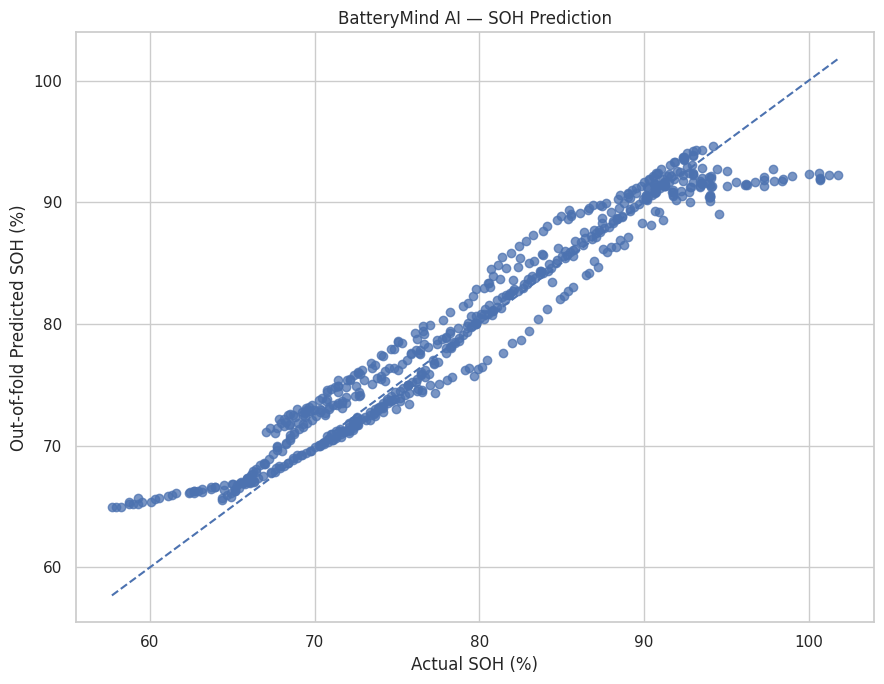

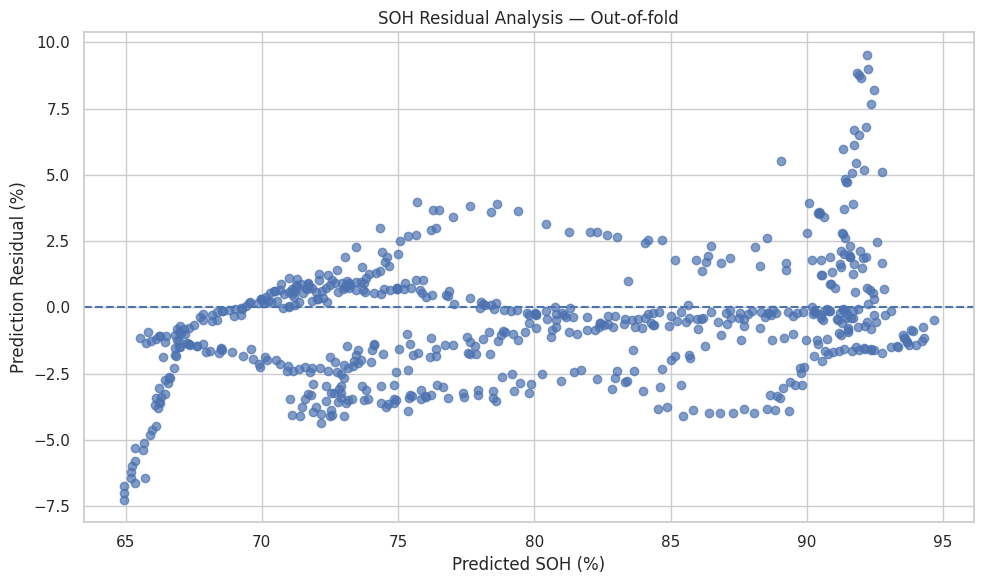


Calculating out-of-fold permutation importance...

FEATURE IMPORTANCE
               Feature          mean          std
discharge_duration_sec  2.771780e+00 1.136300e+00
           cycle_index  1.313639e+00 2.110281e-01
          voltage_mean  9.485880e-01 1.044859e+00
          current_mean  4.433566e-01 5.129758e-01
           current_std  3.428273e-01 3.768128e-01
       temperature_std  2.386254e-01 8.038154e-02
           voltage_min  3.514506e-03 7.373086e-03
         voltage_range  2.591658e-03 5.840548e-03
   ambient_temperature -1.360023e-16 1.176849e-15
      temperature_mean -1.200399e-04 4.109579e-03
       temperature_max -2.825403e-03 1.669775e-02
           voltage_max -3.522453e-03 3.578342e-03
     temperature_range -5.900426e-03 3.167769e-02
           voltage_std -7.771958e-03 1.072327e-02


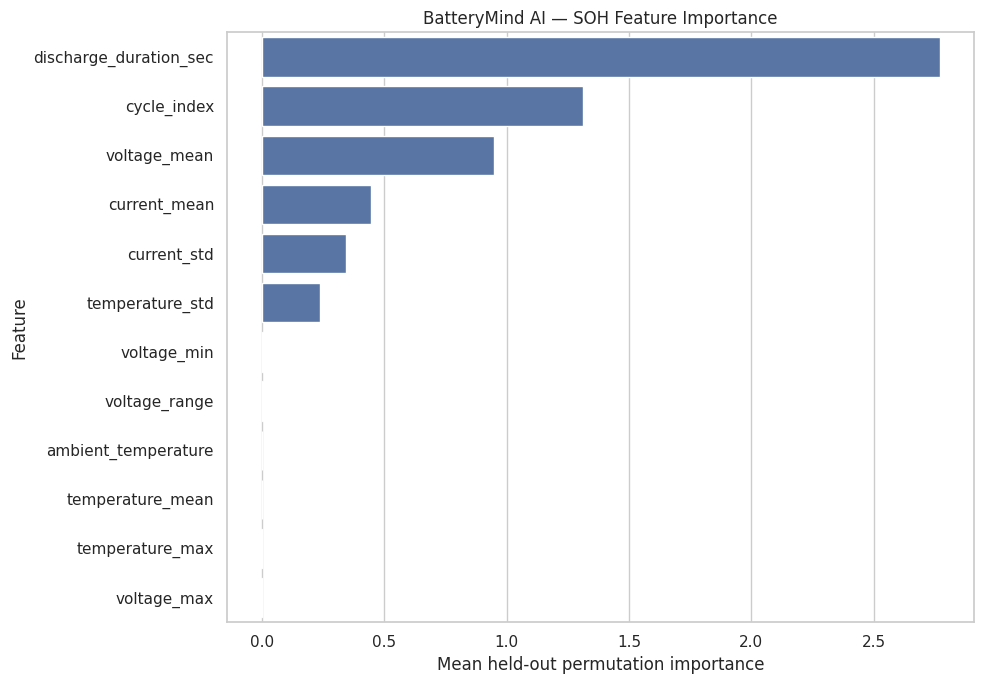

B0007: EOL threshold not observed. Excluded from supervised RUL training.

RUL DATASET SUMMARY
            count  min    max
battery_id                   
B0005         168  0.0  124.0
B0006         168  0.0  108.0
B0018         132  0.0   96.0

REMAINING USEFUL LIFE MODEL TRAINING

Training: Random Forest

Training: Extra Trees

Training: Gradient Boosting

RUL MODEL COMPARISON
            Model       MAE      RMSE       R2
    Random Forest  9.967548 13.256769 0.874161
      Extra Trees 10.505921 13.751511 0.864593
Gradient Boosting 11.011588 13.995263 0.859750


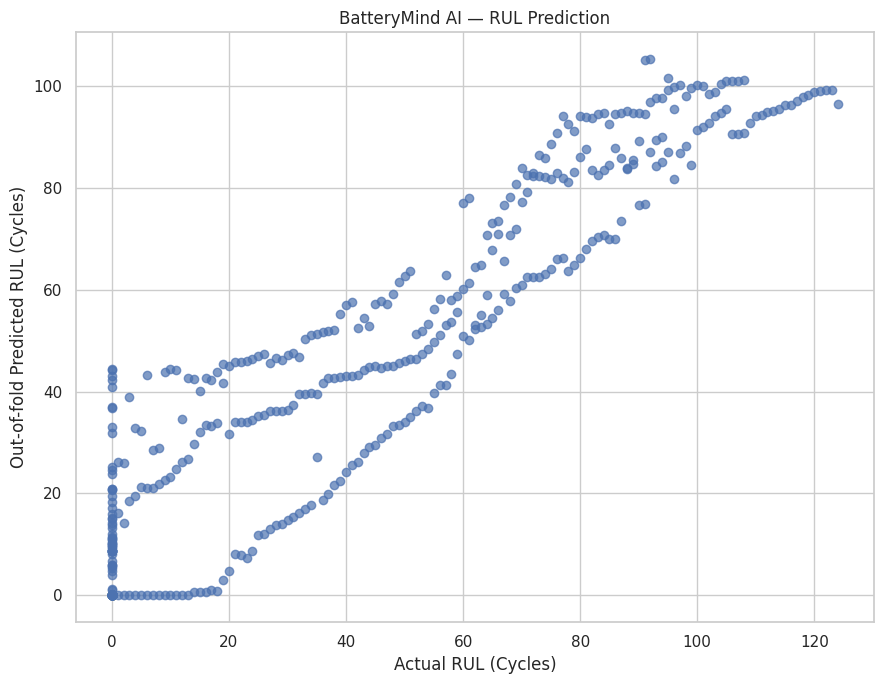


Running Isolation Forest...

ANOMALY COUNTS
anomaly_status
Normal               604
Potential Anomaly     32
Name: count, dtype: int64


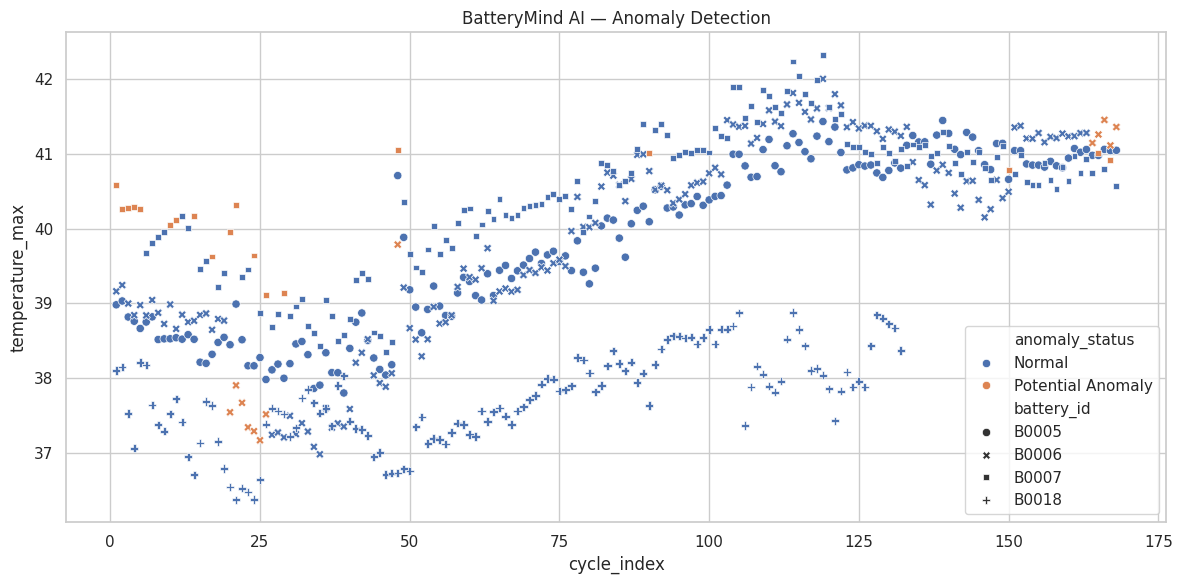


BATTERY COMPARISON
battery_id  total_cycles  initial_capacity  final_capacity  average_soh  average_temperature  capacity_loss
     B0005           168          1.856487        1.325079    78.625103            32.791319       0.531408
     B0006           168          2.035338        1.185675    77.342533            32.792665       0.849662
     B0007           168          1.891052        1.432455    82.221070            32.367751       0.458597
     B0018           132          1.855005        1.341051    77.885038            31.094192       0.513953

BATTERYMIND AI — CUSTOM PREDICTION

Reference battery: B0005
Reference cycle: 70
Reference measured SOH: 81.39 %
Reference labelled RUL: 55 cycles

Enter values or press ENTER to use reference measurements.
cycle_index [70.0000]: 
ambient_temperature [24.0000]: 
voltage_mean [3.5287]: 
voltage_min [2.6430]: 
voltage_max [4.1996]: 
voltage_std [0.2293]: 
voltage_range [1.5566]: 
current_mean [-1.8572]: 
current_std [0.5366]: 
temperatur

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


BATTERYMIND AI FINAL VERSION COMPLETED.


In [4]:

# ================================================================
# BATTERYMIND AI — FINAL MODEL VALIDATION & INTELLIGENCE UPGRADE
# Replaces previous Sections 12–24
# Uses existing NASA dataset and existing df
# ================================================================

import os
import shutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    IsolationForest
)
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.inspection import permutation_importance

# ------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------

BASE_DIR = Path("/content/BatteryMind_AI")

DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
MODEL_DIR = BASE_DIR / "models"
REPORT_DIR = BASE_DIR / "reports"

for folder in [DATA_DIR, OUTPUT_DIR, MODEL_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
EOL_CAPACITY_AH = 1.4
NOMINAL_CAPACITY_AH = 2.0

sns.set_theme(style="whitegrid")

# ------------------------------------------------
# 2. REMOVE FEATURE LEAKAGE
# ------------------------------------------------

df = df.copy()

# Recalculate SOH from measured discharge capacity.
df["SOH"] = (
    df["capacity_ah"] / NOMINAL_CAPACITY_AH
) * 100

df["capacity_fade_percent"] = 100 - df["SOH"]

df["voltage_range"] = (
    df["voltage_max"] - df["voltage_min"]
)

df["temperature_range"] = (
    df["temperature_max"] - df["temperature_mean"]
)

df["capacity_loss_ah"] = (
    NOMINAL_CAPACITY_AH - df["capacity_ah"]
)

# IMPORTANT:
# Do not use cycle_progress because it depends on
# the maximum observed lifetime of the battery.

FEATURES = [
    "cycle_index",
    "ambient_temperature",
    "voltage_mean",
    "voltage_min",
    "voltage_max",
    "voltage_std",
    "voltage_range",
    "current_mean",
    "current_std",
    "temperature_mean",
    "temperature_max",
    "temperature_std",
    "temperature_range",
    "discharge_duration_sec"
]

df = df.replace([np.inf, -np.inf], np.nan)

df = df.dropna(
    subset=["battery_id", "capacity_ah", "cycle_index"]
).reset_index(drop=True)

print("Feature leakage correction completed.")
print("Number of features:", len(FEATURES))
print("Dataset shape:", df.shape)

# ------------------------------------------------
# 3. MODEL DEFINITIONS
# ------------------------------------------------

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=250,
        max_depth=12,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=250,
        max_depth=12,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=150,
        max_leaf_nodes=15,
        learning_rate=0.08,
        random_state=RANDOM_STATE
    )
}

def make_pipeline(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", clone(estimator))
    ])

# ------------------------------------------------
# 4. GROUP-AWARE CROSS-VALIDATION
# ------------------------------------------------

def train_and_evaluate(data, target, feature_columns, model_dict):

    X = data[feature_columns].reset_index(drop=True)
    y = data[target].reset_index(drop=True)
    groups = data["battery_id"].reset_index(drop=True)

    group_count = groups.nunique()

    if group_count < 2:
        raise ValueError("At least two independent battery cells are required.")

    cv = GroupKFold(n_splits=group_count)

    results = []
    oof_predictions = {}
    final_models = {}

    for model_name, estimator in model_dict.items():

        print("\nTraining:", model_name)

        predictions = np.full(len(data), np.nan)

        for train_idx, test_idx in cv.split(X, y, groups):

            X_train = X.iloc[train_idx]
            X_test = X.iloc[test_idx]

            y_train = y.iloc[train_idx]

            model = make_pipeline(estimator)

            model.fit(X_train, y_train)

            fold_predictions = model.predict(X_test)

            # RUL cannot be negative.
            if target == "RUL":
                fold_predictions = np.maximum(
                    fold_predictions, 0
                )

            predictions[test_idx] = fold_predictions

        valid = np.isfinite(predictions)

        actual = y.to_numpy()[valid]
        predicted = predictions[valid]

        mae = mean_absolute_error(actual, predicted)
        rmse = np.sqrt(mean_squared_error(actual, predicted))
        r2 = r2_score(actual, predicted)

        results.append({
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        oof_predictions[model_name] = predictions

        final_model = make_pipeline(estimator)

        final_model.fit(X, y)

        final_models[model_name] = final_model

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        "MAE"
    ).reset_index(drop=True)

    return results_df, oof_predictions, final_models


# ------------------------------------------------
# 5. STATE OF HEALTH MODEL TRAINING
# ------------------------------------------------

print("\n" + "=" * 55)
print("STATE OF HEALTH MODEL TRAINING")
print("=" * 55)

soh_results, soh_predictions, soh_models = train_and_evaluate(
    df,
    "SOH",
    FEATURES,
    models
)

print("\nSOH MODEL COMPARISON")

print(soh_results.to_string(index=False))

best_soh_name = soh_results.iloc[0]["Model"]
best_soh_model = soh_models[best_soh_name]
best_soh_predictions = soh_predictions[best_soh_name]

soh_results.to_csv(
    REPORT_DIR / "soh_model_comparison.csv",
    index=False
)

print("\nSelected model:", best_soh_name)

# ------------------------------------------------
# 6. SOH ACTUAL VS PREDICTED
# ------------------------------------------------

plt.figure(figsize=(9, 7))

plt.scatter(
    df["SOH"],
    best_soh_predictions,
    alpha=0.75
)

low = min(
    df["SOH"].min(),
    np.nanmin(best_soh_predictions)
)

high = max(
    df["SOH"].max(),
    np.nanmax(best_soh_predictions)
)

plt.plot(
    [low, high],
    [low, high],
    linestyle="--"
)

plt.xlabel("Actual SOH (%)")
plt.ylabel("Out-of-fold Predicted SOH (%)")

plt.title("BatteryMind AI — SOH Prediction")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "soh_actual_vs_predicted.png",
    dpi=300
)

plt.show()

# ------------------------------------------------
# 7. SOH RESIDUAL ANALYSIS
# ------------------------------------------------

soh_residuals = (
    df["SOH"].to_numpy() -
    best_soh_predictions
)

plt.figure(figsize=(10, 6))

plt.scatter(
    best_soh_predictions,
    soh_residuals,
    alpha=0.7
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted SOH (%)")
plt.ylabel("Prediction Residual (%)")

plt.title("SOH Residual Analysis — Out-of-fold")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "residual_analysis.png",
    dpi=300
)

plt.show()

# ------------------------------------------------
# 8. FEATURE IMPORTANCE ON HELD-OUT BATTERIES
# ------------------------------------------------

print("\nCalculating out-of-fold permutation importance...")

importance_records = []

groups = df["battery_id"].reset_index(drop=True)
X = df[FEATURES].reset_index(drop=True)
y = df["SOH"].reset_index(drop=True)

cv = GroupKFold(n_splits=groups.nunique())

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups), start=1
):

    fold_model = make_pipeline(models[best_soh_name])

    fold_model.fit(
        X.iloc[train_idx],
        y.iloc[train_idx]
    )

    importance = permutation_importance(
        fold_model,
        X.iloc[test_idx],
        y.iloc[test_idx],
        scoring="neg_mean_absolute_error",
        n_repeats=10,
        random_state=RANDOM_STATE
    )

    for i, feature in enumerate(FEATURES):

        importance_records.append({
            "Fold": fold,
            "Feature": feature,
            "Importance": importance.importances_mean[i]
        })

importance_df = pd.DataFrame(importance_records)

importance_summary = (
    importance_df.groupby("Feature")
    ["Importance"]
    .agg(["mean", "std"])
    .reset_index()
    .sort_values("mean", ascending=False)
)

importance_summary.to_csv(
    REPORT_DIR / "soh_feature_importance.csv",
    index=False
)

print("\nFEATURE IMPORTANCE")

print(importance_summary.to_string(index=False))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_summary.head(12),
    x="mean",
    y="Feature"
)

plt.xlabel("Mean held-out permutation importance")
plt.ylabel("Feature")

plt.title("BatteryMind AI — SOH Feature Importance")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "feature_importance.png",
    dpi=300
)

plt.show()

# ------------------------------------------------
# 9. REMAINING USEFUL LIFE LABELS
# ------------------------------------------------

rul_data = df.copy()

rul_data["EOL_cycle"] = np.nan
rul_data["RUL"] = np.nan

for battery in rul_data["battery_id"].unique():

    mask = rul_data["battery_id"] == battery

    battery_data = (
        rul_data.loc[mask]
        .sort_values("cycle_index")
    )

    eol_rows = battery_data[
        battery_data["capacity_ah"] <= EOL_CAPACITY_AH
    ]

    if eol_rows.empty:

        print(
            f"{battery}: EOL threshold not observed. "
            "Excluded from supervised RUL training."
        )

        continue

    eol_cycle = eol_rows.iloc[0]["cycle_index"]

    rul_data.loc[mask, "EOL_cycle"] = eol_cycle

    rul_data.loc[mask, "RUL"] = (
        eol_cycle -
        rul_data.loc[mask, "cycle_index"]
    ).clip(lower=0)

rul_training = rul_data.dropna(
    subset=["RUL"]
).copy()

print("\nRUL DATASET SUMMARY")

print(
    rul_training.groupby("battery_id")
    ["RUL"]
    .agg(["count", "min", "max"])
)

# ------------------------------------------------
# 10. RUL MODEL TRAINING
# ------------------------------------------------

best_rul_model = None
best_rul_name = None
rul_results = pd.DataFrame()
rul_predictions = {}

if (
    rul_training["battery_id"].nunique() >= 2
    and len(rul_training) >= 10
):

    print("\n" + "=" * 55)
    print("REMAINING USEFUL LIFE MODEL TRAINING")
    print("=" * 55)

    rul_results, rul_predictions, rul_models = train_and_evaluate(
        rul_training,
        "RUL",
        FEATURES,
        models
    )

    print("\nRUL MODEL COMPARISON")

    print(rul_results.to_string(index=False))

    best_rul_name = rul_results.iloc[0]["Model"]
    best_rul_model = rul_models[best_rul_name]

    rul_results.to_csv(
        REPORT_DIR / "rul_model_comparison.csv",
        index=False
    )

    best_rul_predictions = rul_predictions[best_rul_name]

    plt.figure(figsize=(9, 7))

    plt.scatter(
        rul_training["RUL"],
        best_rul_predictions,
        alpha=0.7
    )

    plt.xlabel("Actual RUL (Cycles)")
    plt.ylabel("Out-of-fold Predicted RUL (Cycles)")

    plt.title("BatteryMind AI — RUL Prediction")

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "rul_actual_vs_predicted.png",
        dpi=300
    )

    plt.show()

else:

    print(
        "\nRUL model not trained: insufficient independent "
        "battery cells with observed end-of-life."
    )

# ------------------------------------------------
# 11. BATTERY ANOMALY DETECTION
# ------------------------------------------------

print("\nRunning Isolation Forest...")

anomaly_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("model", IsolationForest(
        n_estimators=200,
        contamination=0.05,
        random_state=RANDOM_STATE
    ))
])

anomaly_pipeline.fit(df[FEATURES])

df["anomaly_label"] = anomaly_pipeline.predict(
    df[FEATURES]
)

df["anomaly_status"] = df["anomaly_label"].map({
    1: "Normal",
    -1: "Potential Anomaly"
})

print("\nANOMALY COUNTS")

print(df["anomaly_status"].value_counts())

anomaly_report = (
    df.groupby(["battery_id", "anomaly_status"])
    .size()
    .unstack(fill_value=0)
)

anomaly_report.to_csv(
    REPORT_DIR / "anomaly_summary.csv"
)

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="cycle_index",
    y="temperature_max",
    hue="anomaly_status",
    style="battery_id"
)

plt.title("BatteryMind AI — Anomaly Detection")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "anomaly_detection.png",
    dpi=300
)

plt.show()

# ------------------------------------------------
# 12. BATTERY DEGRADATION COMPARISON
# ------------------------------------------------

battery_summary = (
    df.groupby("battery_id")
    .agg(
        total_cycles=("cycle_index", "max"),
        initial_capacity=("capacity_ah", "first"),
        final_capacity=("capacity_ah", "last"),
        average_soh=("SOH", "mean"),
        average_temperature=("temperature_mean", "mean")
    )
    .reset_index()
)

battery_summary["capacity_loss"] = (
    battery_summary["initial_capacity"] -
    battery_summary["final_capacity"]
)

battery_summary.to_csv(
    REPORT_DIR / "battery_comparison.csv",
    index=False
)

print("\nBATTERY COMPARISON")

print(battery_summary.to_string(index=False))

# ------------------------------------------------
# 13. CUSTOM BATTERY PREDICTION
# ------------------------------------------------

print("\n" + "=" * 55)
print("BATTERYMIND AI — CUSTOM PREDICTION")
print("=" * 55)

# Choose a genuine mid-life observation where RUL is known.
# This gives a more useful default than the final observed cycle.

if (
    best_rul_model is not None
    and (rul_training["RUL"] > 0).any()
):

    candidates = rul_training[
        rul_training["RUL"] > 0
    ].copy()

    candidates = candidates.sort_values("RUL")

    example_row = candidates.iloc[
        len(candidates) // 2
    ]

else:

    example_row = df.sort_values(
        "SOH"
    ).iloc[len(df) // 2]

print("\nReference battery:", example_row["battery_id"])
print("Reference cycle:", int(example_row["cycle_index"]))

print(
    "Reference measured SOH:",
    round(example_row["SOH"], 2),
    "%"
)

if pd.notna(example_row.get("RUL", np.nan)):

    print(
        "Reference labelled RUL:",
        int(example_row["RUL"]),
        "cycles"
    )

print("\nEnter values or press ENTER to use reference measurements.")

custom_values = {}

for feature in FEATURES:

    default_value = float(example_row[feature])

    user_input = input(
        f"{feature} [{default_value:.4f}]: "
    ).strip()

    if user_input == "":
        custom_values[feature] = default_value
    else:
        custom_values[feature] = float(user_input)

custom_df = pd.DataFrame(
    [custom_values],
    columns=FEATURES
)

custom_soh = float(
    best_soh_model.predict(custom_df)[0]
)

print("\n" + "=" * 45)
print("BATTERYMIND AI PREDICTION REPORT")
print("=" * 45)

print(f"Predicted SOH: {custom_soh:.2f}%")

if custom_soh >= 90:
    print("Estimated category: High SOH")

elif custom_soh >= 80:
    print("Estimated category: Moderate SOH")

elif custom_soh >= 70:
    print("Estimated category: Low SOH")

else:
    print("Estimated category: Below 70% SOH reference")

if best_rul_model is not None:

    custom_rul = float(
        best_rul_model.predict(custom_df)[0]
    )

    custom_rul = max(0, custom_rul)

    print(
        f"Estimated RUL: {custom_rul:.1f} cycles"
    )

else:

    custom_rul = np.nan

    print("RUL estimate unavailable.")

print("=" * 45)

print(
    "Research estimate only. Not a certified "
    "battery health or safety assessment."
)

# ------------------------------------------------
# 14. SAVE FINAL MODELS
# ------------------------------------------------

joblib.dump(
    best_soh_model,
    MODEL_DIR / "battery_soh_model.pkl"
)

joblib.dump(
    anomaly_pipeline,
    MODEL_DIR / "battery_anomaly_model.pkl"
)

if best_rul_model is not None:

    joblib.dump(
        best_rul_model,
        MODEL_DIR / "battery_rul_model.pkl"
    )

joblib.dump(
    FEATURES,
    MODEL_DIR / "feature_columns.pkl"
)

print("\nAll trained models exported.")

# ------------------------------------------------
# 15. SAVE FINAL METRICS
# ------------------------------------------------

soh_metric_row = soh_results.iloc[0]

metric_records = [

    {
        "Task": "SOH",
        "Best Model": best_soh_name,
        "MAE": soh_metric_row["MAE"],
        "RMSE": soh_metric_row["RMSE"],
        "R2": soh_metric_row["R2"]
    }

]

if not rul_results.empty:

    rul_metric_row = rul_results.iloc[0]

    metric_records.append({

        "Task": "RUL",
        "Best Model": best_rul_name,
        "MAE": rul_metric_row["MAE"],
        "RMSE": rul_metric_row["RMSE"],
        "R2": rul_metric_row["R2"]

    })

final_metrics = pd.DataFrame(metric_records)

final_metrics.to_csv(
    REPORT_DIR / "final_metrics.csv",
    index=False
)

df.to_csv(
    REPORT_DIR / "battery_health_analysis.csv",
    index=False
)

rul_training.to_csv(
    REPORT_DIR / "rul_training_data.csv",
    index=False
)

# ------------------------------------------------
# 16. SAVE NOTEBOOK ENVIRONMENT REQUIREMENTS
# ------------------------------------------------

requirements = """numpy
pandas
matplotlib
seaborn
scipy
scikit-learn
joblib
requests
"""

with open(
    BASE_DIR / "requirements.txt",
    "w"
) as file:

    file.write(requirements)

# ------------------------------------------------
# 17. GENERATE FINAL PROJECT ZIP
# ------------------------------------------------

ZIP_OUTPUT = shutil.make_archive(
    "/content/BatteryMind_AI_Final_Day11",
    "zip",
    BASE_DIR
)

# ------------------------------------------------
# 18. FINAL PROJECT SUMMARY
# ------------------------------------------------

print("\n" + "=" * 60)
print("BATTERYMIND AI — FINAL EXECUTION SUMMARY")
print("=" * 60)

print("Dataset records:", len(df))
print("Battery cells:", df["battery_id"].nunique())
print("Total features:", len(FEATURES))

print("\nSOH BEST MODEL:", best_soh_name)

print("SOH MAE:", round(soh_metric_row["MAE"], 4))
print("SOH RMSE:", round(soh_metric_row["RMSE"], 4))
print("SOH R2:", round(soh_metric_row["R2"], 4))

if best_rul_model is not None:

    print("\nRUL BEST MODEL:", best_rul_name)

    print(
        "RUL MAE:",
        round(rul_metric_row["MAE"], 4)
    )

    print(
        "RUL RMSE:",
        round(rul_metric_row["RMSE"], 4)
    )

    print(
        "RUL R2:",
        round(rul_metric_row["R2"], 4)
    )

print("\nPROJECT ZIP:", ZIP_OUTPUT)

print("\nAll outputs exported successfully.")

# ------------------------------------------------
# 19. DOWNLOAD FINAL PROJECT
# ------------------------------------------------

from google.colab import files

files.download(ZIP_OUTPUT)

print("\nBATTERYMIND AI FINAL VERSION COMPLETED.")


In [5]:
import os
import zipfile
from google.colab import files

BASE_DIR = "/content/BatteryMind_AI"
ZIP_PATH = "/content/BatteryMind_AI_GitHub_Ready.zip"

if not os.path.exists(BASE_DIR):
    print("Project folder not found.")
    print("Folders available in /content:")
    print(os.listdir("/content"))
else:
    excluded_dirs = {
        "data", "__pycache__", ".ipynb_checkpoints", ".git"
    }

    excluded_extensions = {".mat", ".zip", ".tmp", ".log"}

    with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
        for root, dirs, filenames in os.walk(BASE_DIR):
            dirs[:] = [
                d for d in dirs if d not in excluded_dirs
            ]

            for filename in filenames:
                filepath = os.path.join(root, filename)

                if os.path.splitext(filename)[1].lower() in excluded_extensions:
                    continue

                arcname = os.path.relpath(filepath, BASE_DIR)
                zf.write(filepath, arcname)

    print("GitHub-ready ZIP created successfully!")
    print("File size:", round(os.path.getsize(ZIP_PATH) / (1024 * 1024), 2), "MB")

    files.download(ZIP_PATH)

GitHub-ready ZIP created successfully!
File size: 7.59 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>